# Project 1: Transactions – Pass 03



## Problem Definition



#### 1. State the business problem.

Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.  Mention which model will be used, if known.



> We want to predict whether or not a future customer will complete a transaction (e.g., a product purchase, loan or bill payment, or subscription retention) based on prior transaction data. Such predictions can help determine higher-risk customers and present incentives to drive future transaction completions and increase sales.

> This is a supervised, categorical binary classification problem, where the target data is whether a customer transaction was successful (true or false). To achieve this, it uses a Gaussian Naive Bayes model to make predictions about transaction success.




## Data Collection



#### 2. Load Pandas, Numpy, and Matplotlib modules

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

#### 3. Load data Train.csv from AWS S3.

In [2]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.csv'

- Set number of columns and rows for this pass:

In [7]:
# set cols and rows for pass
num_rows = 10_000
num_rows

10000

- Read in the data from .csv using pandas:

In [8]:
# make dataframe
df = pd.read_csv(
    url,
    nrows=num_rows,
)

- Check the dataframe:

In [9]:
# check dataframe
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,train_9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,9996,train_9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,9997,train_9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,9998,train_9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


So our data set has 53 total columns, 50 of these (var_0 - var_49) being feature columns.

## Data Cleaning



#### 4. Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



In [11]:
# define target_col
target_col = 'target'
target_col

'target'

- head

In [12]:
# head
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974


- tail

In [13]:
# tail
df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
9995,9995,train_9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,9996,train_9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,9997,train_9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,9998,train_9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259
9999,9999,train_9999,0,6.1476,3.8616,15.0005,5.3341,6.0115,13.8576,5.5113,...,6.0071,4.5697,-10.4171,24.7558,3.1771,24.9902,-2.6686,5.7259,-0.0793,17.0559


- shape

In [14]:
# shape
df.shape

(10000, 53)

- size

In [15]:
# size
df.size

530000

- info

In [16]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 53 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  10000 non-null  int64  
 1   ID_code     10000 non-null  object 
 2   target      10000 non-null  int64  
 3   var_0       10000 non-null  float64
 4   var_1       10000 non-null  float64
 5   var_2       10000 non-null  float64
 6   var_3       10000 non-null  float64
 7   var_4       10000 non-null  float64
 8   var_5       10000 non-null  float64
 9   var_6       10000 non-null  float64
 10  var_7       10000 non-null  float64
 11  var_8       10000 non-null  float64
 12  var_9       10000 non-null  float64
 13  var_10      10000 non-null  float64
 14  var_11      10000 non-null  float64
 15  var_12      10000 non-null  float64
 16  var_13      10000 non-null  float64
 17  var_14      10000 non-null  float64
 18  var_15      10000 non-null  float64
 19  var_16      10000 non-null

- describe

In [17]:
# describe
df.describe()

,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,...,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,4999.50000,0.099400,10.672717,-1.621588,10.709760,5.403145,7.578393,14.023742,8.450948,15.241111,...,5.640239,0.064045,-0.645431,20.288756,2.622496,12.633719,3.245790,7.457053,1.944307,15.882229
std,2886.89568,0.299213,3.041680,4.077271,2.638402,0.870482,1.244798,0.189263,4.610527,7.811549,...,0.369266,4.383463,5.979894,7.174538,2.806740,9.319561,4.585233,3.039712,1.476938,3.008292
min,0.00000,0.000000,1.335000,-13.422700,3.309000,2.673300,4.287700,13.553100,-3.964100,-7.903300,...,4.569700,-13.472700,-20.410900,-0.852500,-6.143000,-17.356000,-11.593900,-1.215800,-3.515900,7.233700
25%,2499.75000,0.000000,8.452675,-4.779075,8.723700,4.766850,6.606650,13.893000,4.983600,9.169025,...,5.377900,-3.170225,-4.931850,15.048850,0.682275,5.485875,-0.106575,5.151700,0.919650,13.855300
50%,4999.50000,0.000000,10.515750,-1.600700,10.543200,5.387700,7.647950,14.025250,8.518100,15.250950,...,5.637100,0.123300,-0.564750,20.287350,2.542650,12.403650,3.290200,7.356400,1.933300,15.915950
75%,7499.25000,0.000000,12.759675,1.360375,12.517650,5.998100,8.613200,14.162900,12.164025,21.033200,...,5.911500,3.131175,3.599450,25.777150,4.402950,19.286650,6.420875,9.532025,2.966875,18.088900
max,9999.00000,1.000000,19.289300,8.584900,18.347700,7.875500,10.827400,14.595400,21.311900,36.341300,...,6.775900,15.091800,17.086200,40.289100,12.968400,40.586600,16.614400,16.398500,7.139000,25.442200


- nunique

In [18]:
# nunique
df.nunique()

,0
Unnamed: 0,10000
ID_code,10000
target,2
var_0,9557
var_1,9641
var_2,9467
var_3,8520
var_4,8983
var_5,5311
var_6,9674


- unique

In [19]:
# unique
df[target_col].unique()

array([0, 1])

- isnull

In [20]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
Unnamed: 0,0
ID_code,0
target,0
var_0,0
var_1,0
var_2,0
var_3,0
var_4,0
var_5,0
var_6,0


In [21]:
# isnull frequencies
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Unnamed: 0,0.0
ID_code,0.0
target,0.0
var_0,0.0
var_1,0.0
var_2,0.0
var_3,0.0
var_4,0.0
var_5,0.0
var_6,0.0


- dtypes

In [22]:
# dtypes
df.dtypes

,0
Unnamed: 0,int64
ID_code,object
target,int64
var_0,float64
var_1,float64
var_2,float64
var_3,float64
var_4,float64
var_5,float64
var_6,float64


#### 5. NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [23]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
target,
0,9006
1,994


In [24]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True )

,proportion
target,
0,0.9006
1,0.0994


In [25]:
# target col size/shape
df[[target_col]].shape[0]

10000

In [27]:
# sum of nulls in target
df[[target_col]].isnull().sum()

,0
target,0


- Summary:

  - target column: 'target'
  - feature columns: 'var_0' - 'var_49'
  - identifier columns (likely): 'Unnamed', 'ID_code'
  - null columns: n/a
  - null rows: n/a

  Still no null values this pass.

#### 6. If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [28]:
# head again to double-check
df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974


In [31]:
# 'Unnamed' and 'ID_code are very likely identifier columns, and should be dropped

# target and var_0 - var_49 are meaningful data columns and will be kept

- backup 1

In [29]:
# make backup
df_bak = df.copy()
df_bak

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,train_9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,9996,train_9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,9997,train_9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,9998,train_9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


In [30]:
# restore from backup
df = df_bak.copy()
df

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,train_0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,1,train_1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,2,train_2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,3,train_3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,4,train_4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,train_9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,9996,train_9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,9997,train_9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,9998,train_9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


- This pass, keep the target and all 50 features:

In [32]:
# keep the target and all features
df = df.drop( columns = ['Unnamed: 0', 'ID_code'] )

In [33]:
# check our dataframe (display transformed df)
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,15.6440,28.7052,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,16.1281,24.1290,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,31.4915,19.9258,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,27.7635,20.2590,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


- backup 2

In [34]:
# backup 2
df_bak2 = df.copy()
df_bak2

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,15.6440,28.7052,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,16.1281,24.1290,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,31.4915,19.9258,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,27.7635,20.2590,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


In [35]:
# restore from backup 2
df = df_bak2.copy()
df

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,15.6440,28.7052,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,16.1281,24.1290,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,31.4915,19.9258,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,27.7635,20.2590,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


In [36]:
# No rows have nulls, so we can skip imputing with fillna() and/or dropping rows

## Exploratory Data Analysis

Produce some visual analysis of the data.  Recall that Gaussian Naive Bayes assumes the features are normally distributed and independent. Note: you might have to do multiple plots in groups.



#### 7. Check the distributions of all variables by plotting.

array([[<Axes: title={'center': 'target'}>,
        <Axes: title={'center': 'var_0'}>,
        <Axes: title={'center': 'var_1'}>,
        <Axes: title={'center': 'var_2'}>,
        <Axes: title={'center': 'var_3'}>,
        <Axes: title={'center': 'var_4'}>,
        <Axes: title={'center': 'var_5'}>],
       [<Axes: title={'center': 'var_6'}>,
        <Axes: title={'center': 'var_7'}>,
        <Axes: title={'center': 'var_8'}>,
        <Axes: title={'center': 'var_9'}>,
        <Axes: title={'center': 'var_10'}>,
        <Axes: title={'center': 'var_11'}>,
        <Axes: title={'center': 'var_12'}>],
       [<Axes: title={'center': 'var_13'}>,
        <Axes: title={'center': 'var_14'}>,
        <Axes: title={'center': 'var_15'}>,
        <Axes: title={'center': 'var_16'}>,
        <Axes: title={'center': 'var_17'}>,
        <Axes: title={'center': 'var_18'}>,
        <Axes: title={'center': 'var_19'}>],
       [<Axes: title={'center': 'var_20'}>,
        <Axes: title={'center': 'var_21

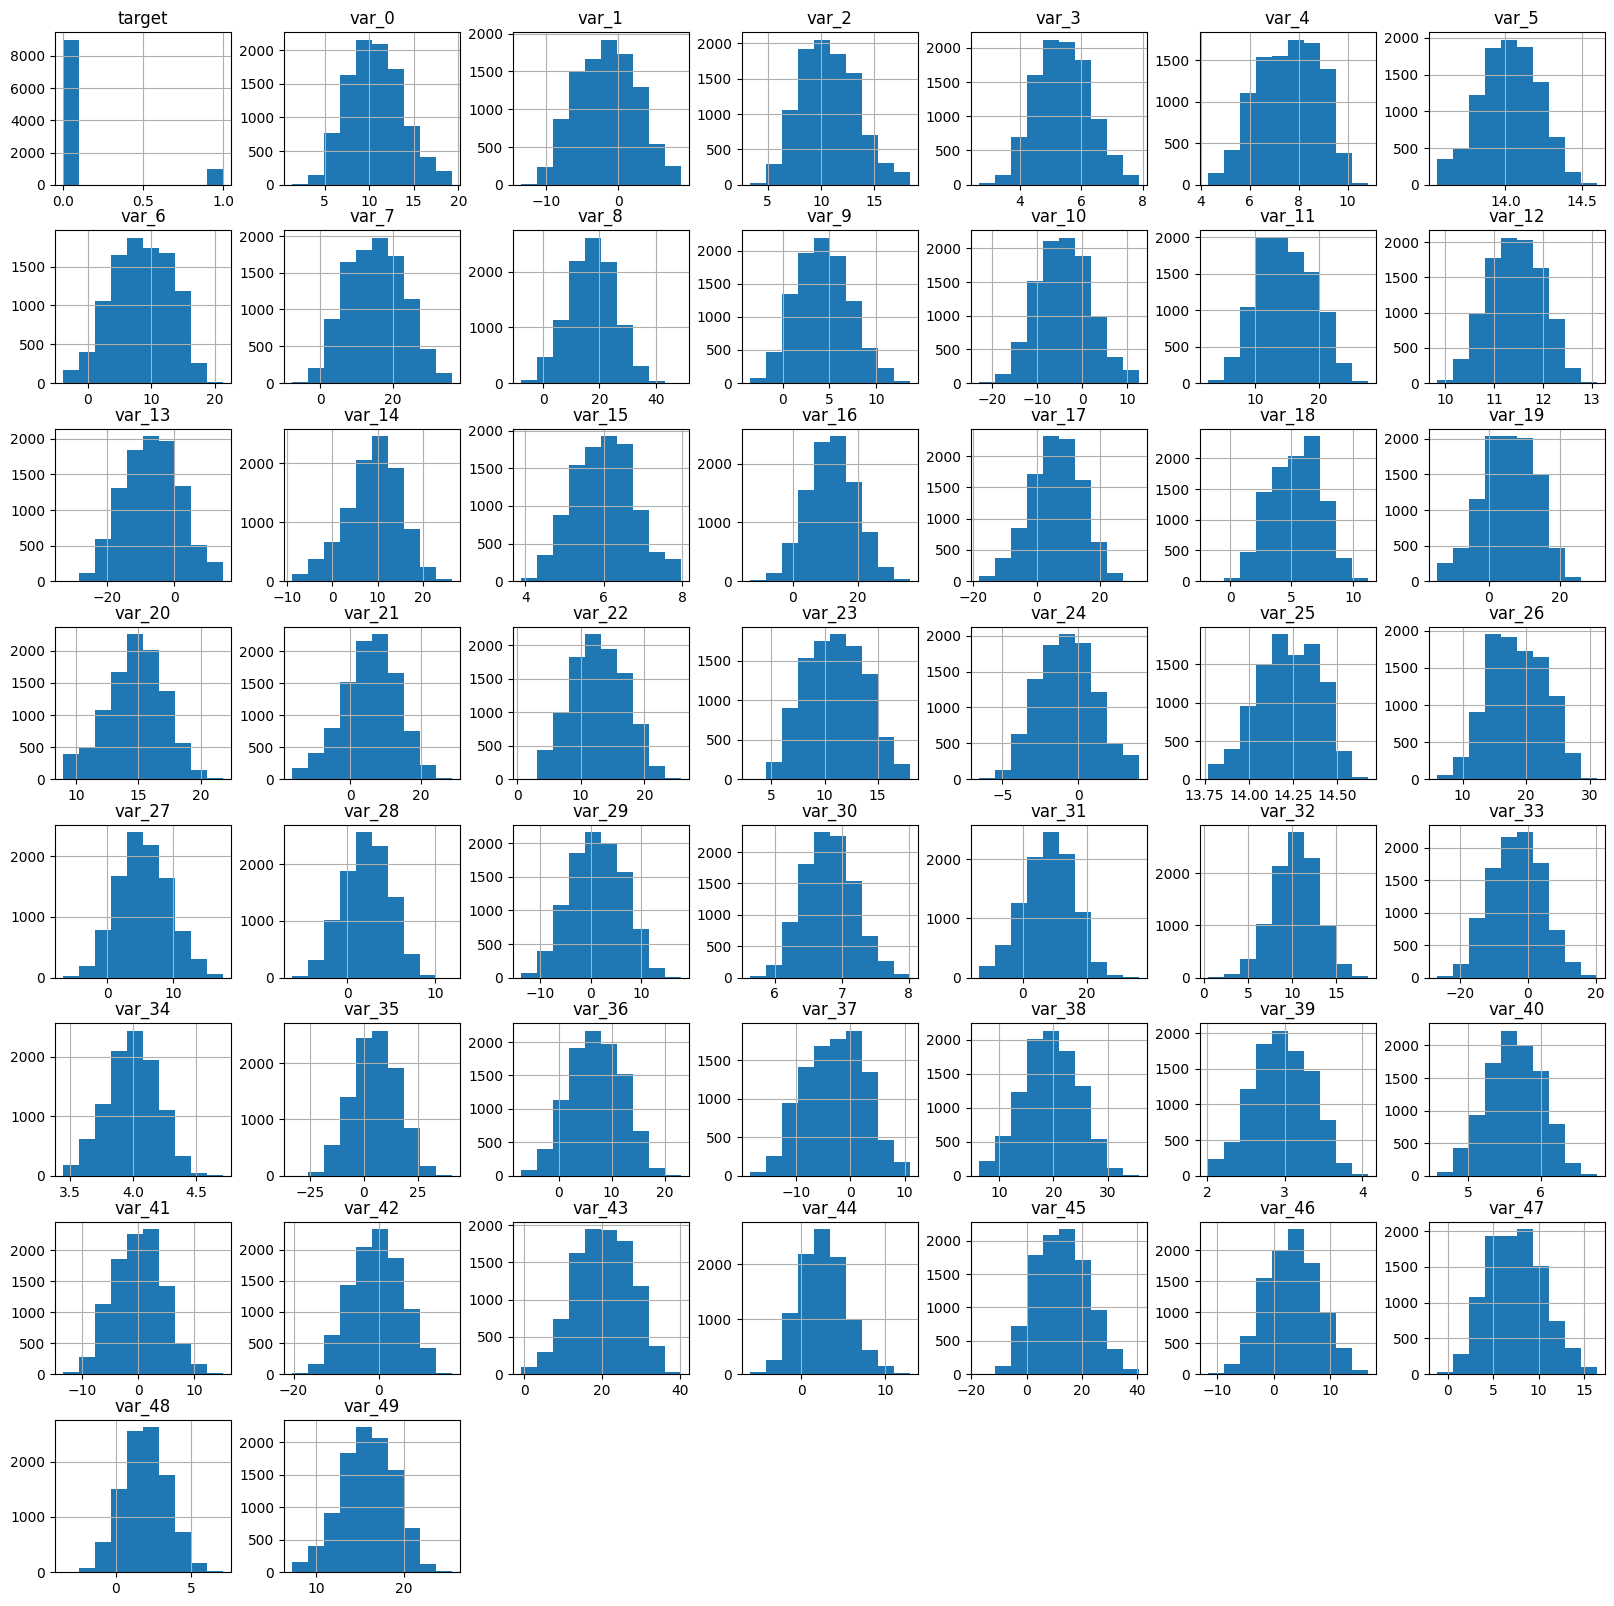

In [42]:
# Display a histogram
df.hist(figsize=(20, 20))

<Axes: >

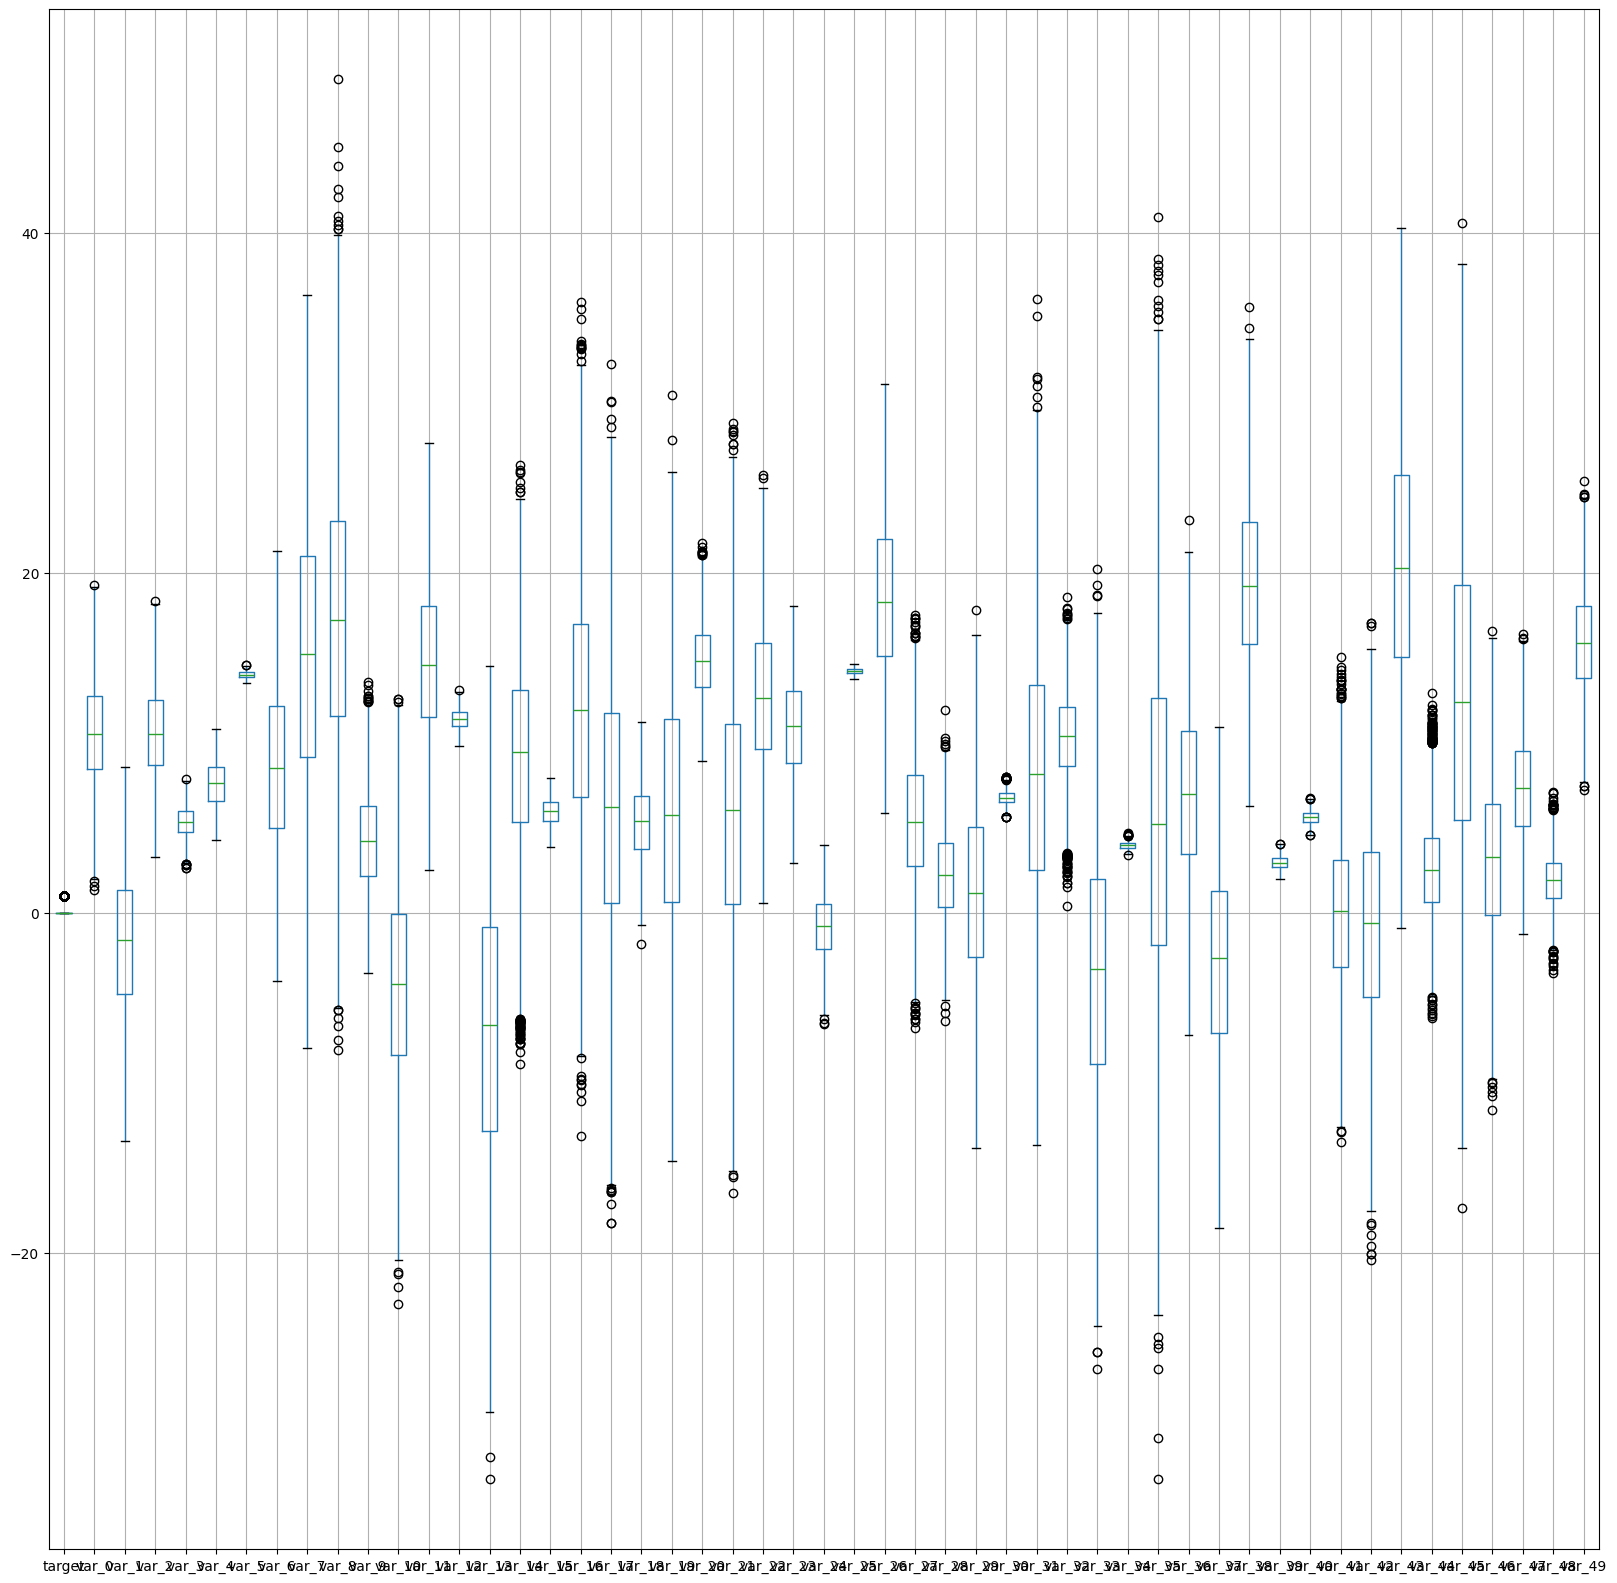

In [43]:
# display a boxplot
df.boxplot(figsize=(20, 20))

#### 8. Check the correlation values between all **feature columns** to ensure there are no substantial correlations between features. This is important to support the decision to classify the ‘target’ using Naïve Bayes.



In [44]:
# column correlations
column_correlations = df.corr()
column_correlations

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
target,1.000000,0.043574,0.066114,0.059939,0.038732,-0.028126,-0.052735,-0.049049,0.052472,-0.060138,...,-0.048415,0.046831,0.046523,-0.052515,0.045255,0.050636,0.055105,0.029874,-0.038527,-0.039557
var_0,0.043574,1.000000,-0.009854,0.011217,-0.008830,-0.011991,-0.004008,-0.005610,0.010324,0.002143,...,-0.017735,0.008473,0.013734,0.021657,0.011481,-0.007350,-0.001388,0.010983,-0.003014,-0.006168
var_1,0.066114,-0.009854,1.000000,0.025620,-0.001012,-0.007787,-0.002027,-0.018065,-0.004419,0.024228,...,-0.012141,0.000944,0.010871,0.001363,-0.010561,-0.014996,0.011586,0.015015,-0.007402,-0.010730
var_2,0.059939,0.011217,0.025620,1.000000,0.004626,0.003042,0.009377,-0.014958,-0.002831,-0.010006,...,-0.015676,-0.001984,0.008702,-0.002698,-0.014033,0.006582,0.000033,0.019182,-0.006128,0.023475
var_3,0.038732,-0.008830,-0.001012,0.004626,1.000000,-0.011308,0.004225,-0.014157,-0.007376,0.001228,...,-0.012295,0.013620,-0.001306,0.002114,-0.006729,0.002133,0.007527,0.018795,-0.005085,0.013717
var_4,-0.028126,-0.011991,-0.007787,0.003042,-0.011308,1.000000,-0.020643,-0.004096,-0.001834,0.003835,...,0.006545,-0.000525,-0.011105,0.002464,0.001220,-0.004567,-0.013192,0.022225,-0.008804,0.014925
var_5,-0.052735,-0.004008,-0.002027,0.009377,0.004225,-0.020643,1.000000,0.015994,0.016200,0.002981,...,0.000999,-0.003686,-0.002560,-0.002469,-0.001667,0.023947,0.009096,-0.016727,0.014813,-0.008814
var_6,-0.049049,-0.005610,-0.018065,-0.014958,-0.014157,-0.004096,0.015994,1.000000,-0.002434,0.006529,...,-0.000391,-0.003957,-0.000081,0.013318,-0.002290,-0.004444,0.010051,-0.005251,0.014332,0.008234
var_7,0.052472,0.010324,-0.004419,-0.002831,-0.007376,-0.001834,0.016200,-0.002434,1.000000,-0.019602,...,-0.000739,0.016092,-0.009378,0.009921,-0.005740,-0.011136,0.016135,0.006741,-0.002834,0.002422
var_8,-0.060138,0.002143,0.024228,-0.010006,0.001228,0.003835,0.002981,0.006529,-0.019602,1.000000,...,0.013479,-0.006359,-0.007322,0.020018,-0.004483,0.003823,0.003681,-0.001141,-0.001220,0.007712


<Axes: >

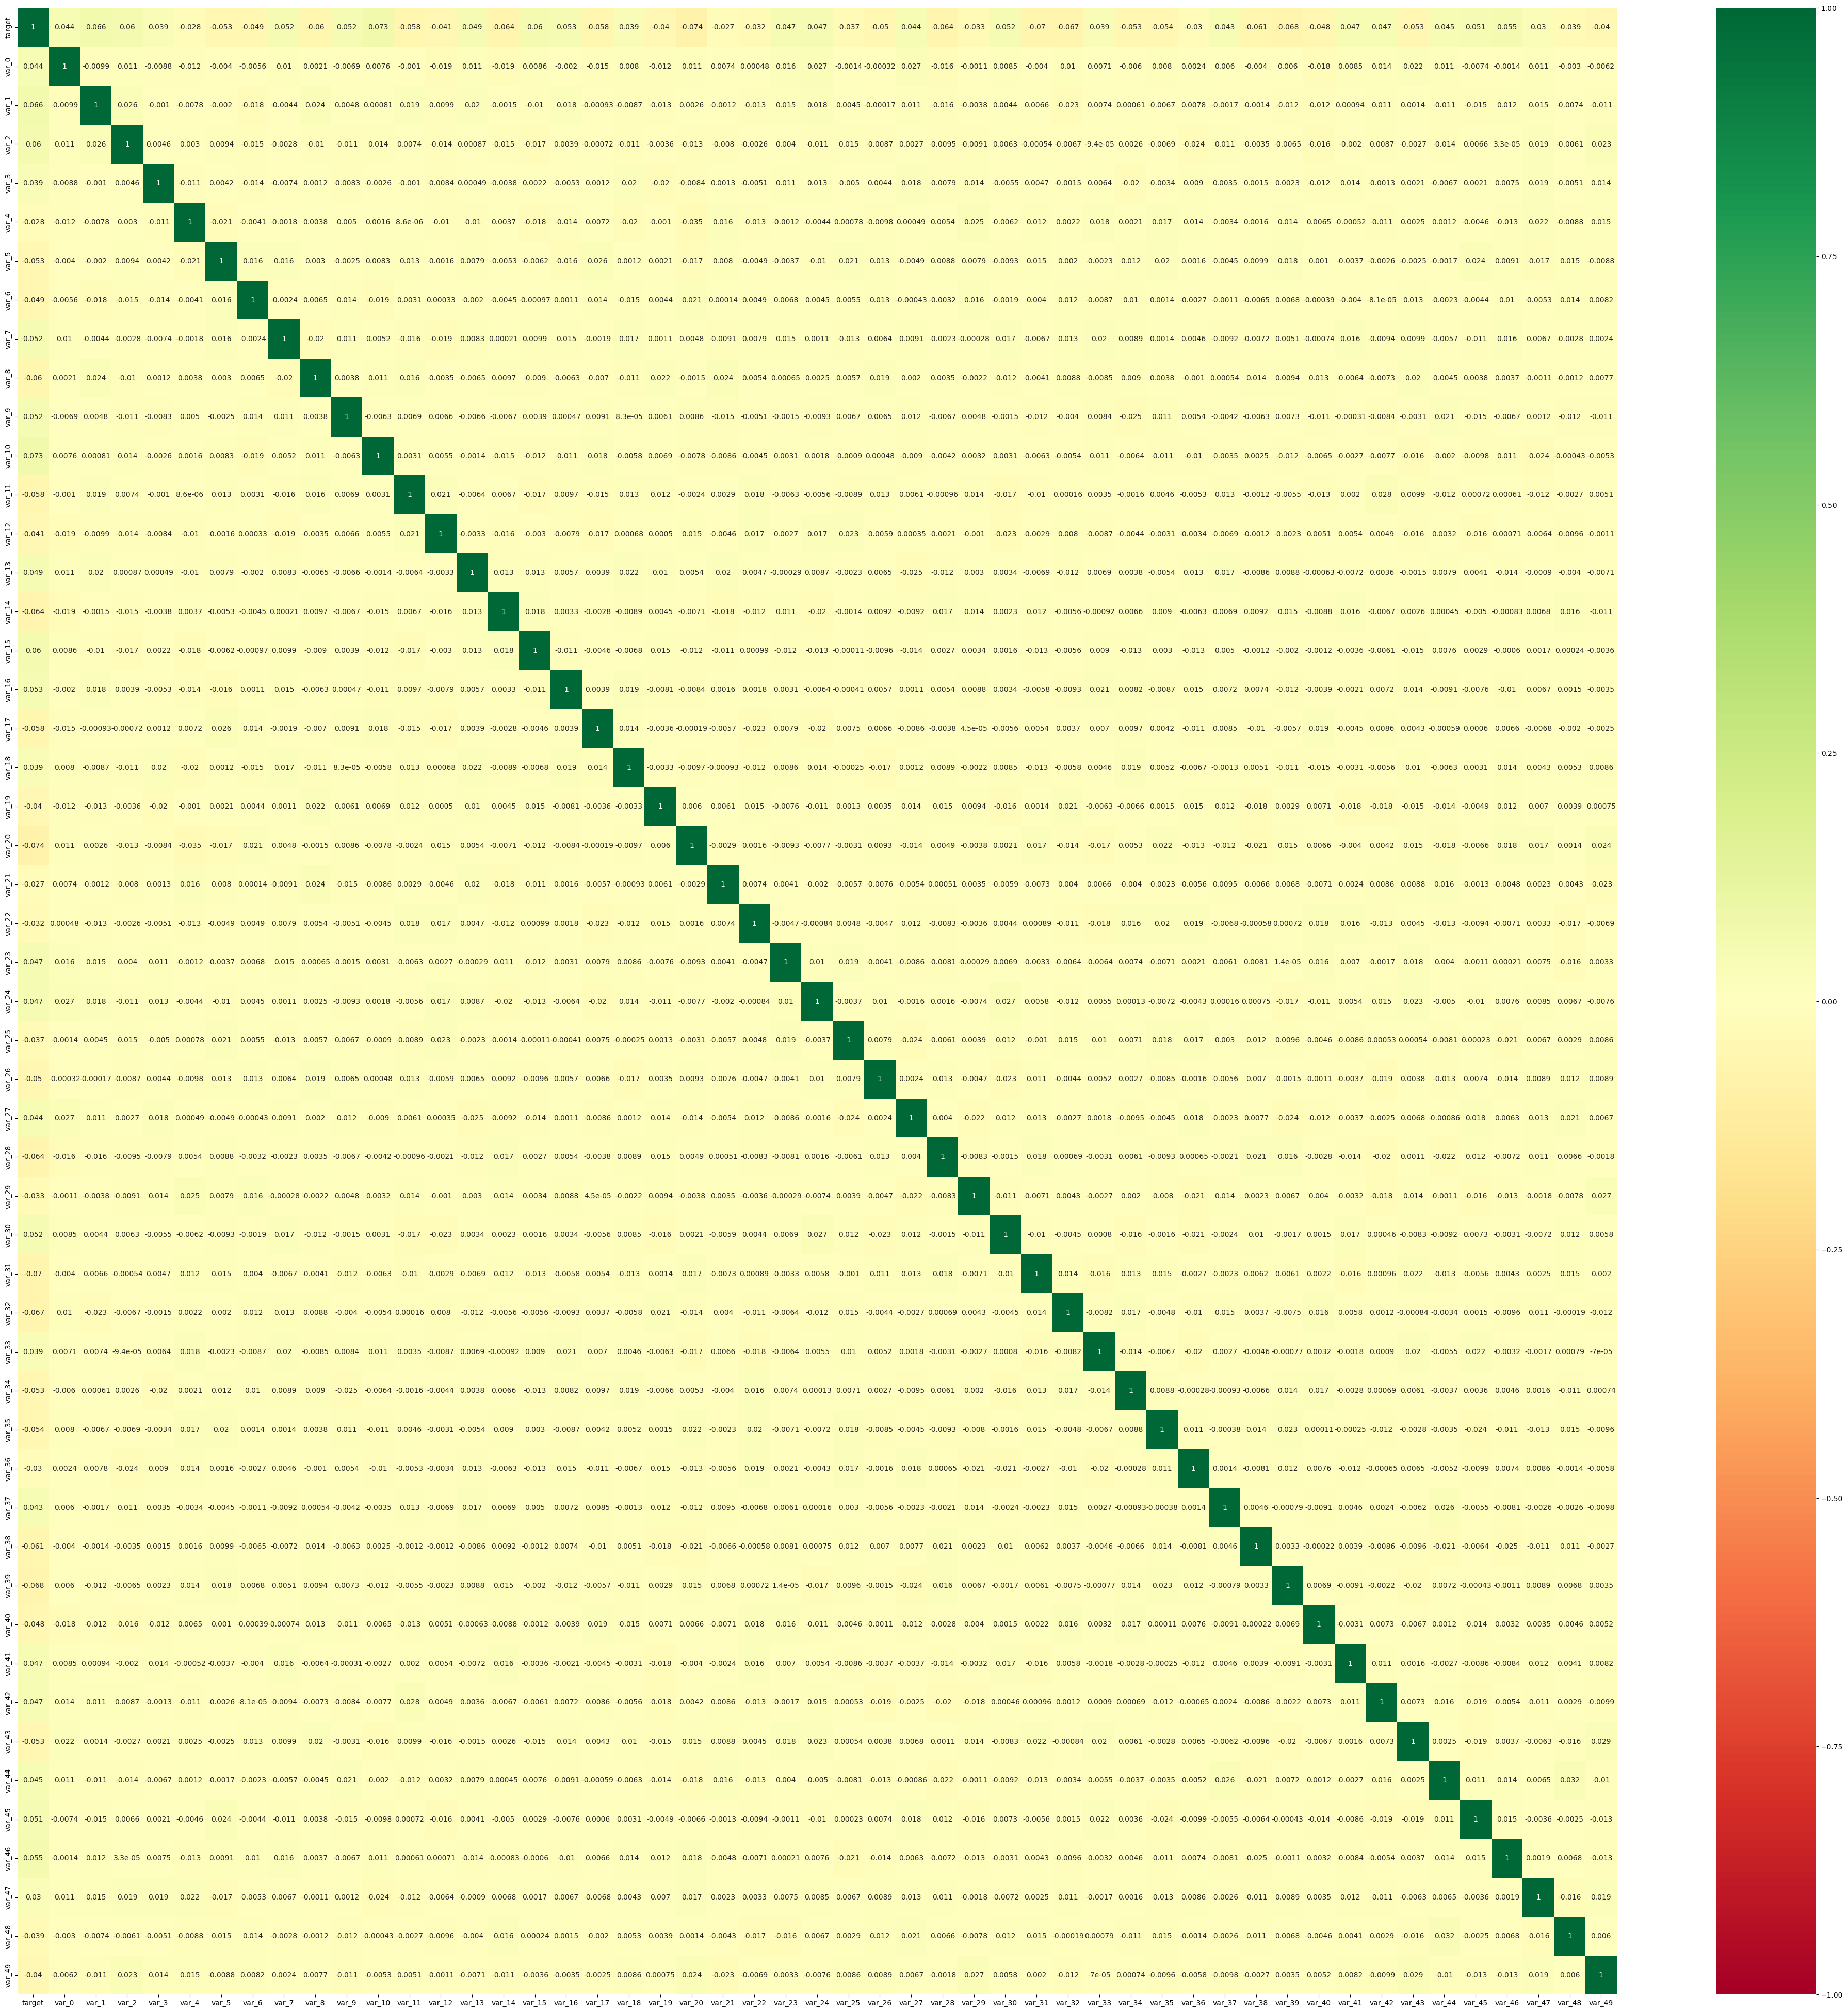

In [46]:
# Display correlation matrix
plt.figure(figsize = (50, 50))
sns.heatmap(
    column_correlations,
    annot = True,
    vmin = -1,
    vmax = 1,
    cmap = 'RdYlGn'
)

#### 9. Create two data frames: one with all successful transactions, one with all unsuccessful transactions. **Make sure they are copies and not slices**.




In [47]:
# make successful (copy)
df_successful   = df[ df[target_col] == 1 ].copy()
df_successful

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
13,1,16.3699,1.5934,16.7395,4.8222,8.6978,13.7999,2.7925,14.3984,19.4258,...,5.6656,3.5750,-2.2723,15.7383,8.5618,11.8982,7.4002,7.4031,4.3989,15.6064
29,1,5.3301,-2.6064,13.1913,5.9064,9.1168,14.0957,12.3335,1.6610,13.0446,...,5.4183,8.6643,4.1428,4.7056,4.3694,16.4554,5.9215,7.9676,2.3405,17.4105
63,1,7.7072,0.0183,9.9974,6.0425,6.6710,14.0503,9.0144,-2.3445,23.5101,...,6.0669,2.5841,2.2445,23.1283,2.9384,27.6213,1.5832,5.0039,3.8814,15.7685
65,1,10.5358,-2.5439,8.7394,5.1584,9.0358,13.6021,4.2864,13.8723,2.2106,...,6.1149,2.2550,-7.2104,19.7545,6.3190,11.9410,4.6648,6.4227,3.4025,15.1340
71,1,6.7547,2.5973,14.2141,4.2336,9.1282,13.9394,3.6480,24.2658,33.3687,...,5.0565,11.9429,0.3140,20.4828,7.9488,11.2587,1.4677,3.5935,2.0013,18.9013
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9966,1,13.0909,-0.3547,9.9865,2.8296,7.6476,13.5542,5.4715,14.5697,7.5045,...,5.3519,-3.0546,-7.5908,27.5548,6.2159,28.0740,14.6078,6.1989,1.1384,15.2719
9981,1,10.3928,3.5668,14.5281,6.3760,6.8565,14.2682,-2.0743,8.8639,22.1958,...,5.7767,-0.7331,-4.5036,23.6651,0.2738,18.9954,4.3423,11.5738,2.3484,14.2065
9983,1,9.4085,-5.8620,9.6223,4.9577,7.1987,13.9489,3.8536,32.2719,22.5744,...,5.7814,-1.1527,-5.9737,26.3907,2.6979,-5.0480,12.3421,3.0314,-0.6105,13.0199
9988,1,11.1396,-5.7085,7.9560,5.5590,7.9828,14.1399,16.7437,24.6136,16.1721,...,5.4543,0.8765,-7.1041,17.4430,6.3916,36.5531,-2.9489,11.7000,1.7016,19.4084


In [48]:
# make unsuccessful (copy)
df_unsuccessful = df[ df[target_col] == 0 ].copy()
df_unsuccessful

,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,0,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,0,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,0,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,0,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,15.6440,28.7052,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,0,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,16.1281,24.1290,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,0,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,31.4915,19.9258,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,0,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,27.7635,20.2590,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


## Data Processing



### Single Cross-validation ( CV )



#### 10. Create two data sets: one with all the feature columns (everything except for Unnamed: 0, ID_code and target) and one with just the target. Make sure they are copies and not slices.  And make sure they are the correct dimensions.



In [49]:
# make target and features
target   = df[ target_col ].copy()
features = df.drop( columns = [target_col] ).copy()

In [50]:
# check target
target

,target
0,0
1,0
2,0
3,0
4,0
...,...
9995,0
9996,0
9997,0
9998,0


In [51]:
# check target value counts
target.value_counts()

,count
target,
0,9006
1,994


In [52]:
# check target dimensions and type
type(target), target.shape, target.ndim

(pandas.core.series.Series, (10000,), 1)

In [53]:
# check features
features

,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,...,var_40,var_41,var_42,var_43,var_44,var_45,var_46,var_47,var_48,var_49
0,8.9255,-6.7863,11.9081,5.1187,5.7470,14.0137,0.5745,4.2840,16.2191,2.5791,...,5.4879,-4.7645,3.1531,18.5618,1.7202,25.8398,4.4354,3.9642,3.1364,12.7803
1,11.5006,-4.1473,13.8588,5.6208,8.0851,14.0239,8.4135,7.8000,2.7407,8.5524,...,5.7999,5.5378,5.5134,30.2645,11.0752,22.5441,7.6421,7.7214,2.5837,18.3560
2,8.6093,-2.7457,12.0805,6.9427,5.9525,14.1929,7.3124,4.7011,18.1377,1.2145,...,5.7690,-7.0927,-5.8234,25.6820,2.4013,23.0866,2.9057,9.7905,1.6704,14.7222
3,11.0604,-2.1518,8.9522,5.8428,8.2450,13.8463,11.9704,15.9426,12.5579,6.8202,...,5.3430,-7.1541,11.7134,14.7483,5.6961,-0.4639,4.4666,4.7433,0.7178,17.9697
4,9.8369,-1.4834,12.8746,5.9405,7.6784,13.8481,7.8895,6.5263,18.9608,10.1102,...,5.5518,1.4493,2.3705,18.4685,5.1743,11.8503,-1.4905,9.5214,-0.1508,17.9974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,16.0253,-2.7417,13.0579,4.6907,7.6733,14.4044,4.4485,15.6440,28.7052,4.5230,...,5.4078,-6.0609,5.3959,14.3071,0.7175,0.8099,3.0246,6.3355,1.2195,15.0416
9996,8.2377,5.8972,11.4494,6.0994,5.8279,14.2108,10.4431,16.1281,24.1290,4.1572,...,6.5495,-3.7137,-2.4108,22.0010,6.6314,7.7139,2.1874,11.9021,3.3370,15.4100
9997,7.4000,-0.5939,5.4020,5.4715,8.9772,13.7754,0.5061,31.4915,19.9258,1.0844,...,5.7283,-3.6798,1.2850,11.7876,0.3499,23.6263,2.4554,7.4933,1.0810,19.3749
9998,7.7726,-4.0555,8.6391,6.4168,8.1651,13.8262,8.7265,27.7635,20.2590,8.4112,...,5.5500,3.6771,7.1521,13.3076,2.2369,19.4285,7.5065,6.9602,3.7997,19.1259


In [54]:
# check features dimensions and type
type(features), features.shape, features.ndim

(pandas.core.frame.DataFrame, (10000, 50), 2)

#### 11. Define an empty Gaussian Naïve Bayes model using Sklearn.



In [55]:
# Create an empty GNB model
modelGNB = GaussianNB()

#### 12. Divide the two data sets you created in step #10 into training and testing subsets, i.e. train-test split.



In [56]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split( features, target, test_size = 0.25 )

#### 13. Train ( fit ) the model using the training subset of the dataset.



In [57]:
# Train ( fit ) the model
modelGNB.fit(X_train, y_train)

GaussianNB()

#### 14. Test the model ( predict ) using the testing subset of the dataset.



In [58]:
# Make predictions using the model
y_pred = modelGNB.predict(X_test)

#### 15. Calculate and report the accuracy.



In [59]:
# Calculate the accuracy
accuracy = metrics.accuracy_score(y_test, y_pred)
accuracy

0.9076

#### 16. Present a confusion matrix and heatmap



Text(113.9222222222222, 0.5, 'Predicted')

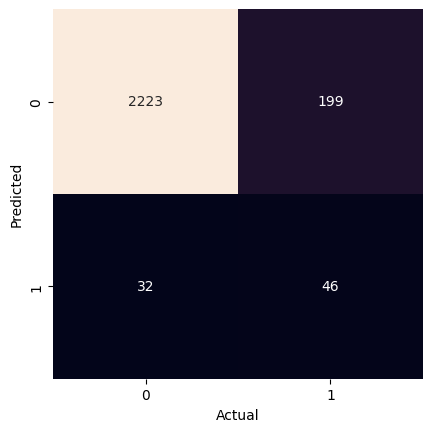

In [60]:
# Display confusion matrix
matrix = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(
    matrix.T,
    square = True,
    annot = True,
    fmt = 'd',
    cbar = False
)
plt.xlabel('Actual')
plt.ylabel('Predicted')

#### 17. Present the results of a Classification Report (sklearn.metrics.classification_report).

In [61]:
# 1. Generate the report (as a dictionary, for formatting)
report = metrics.classification_report(y_test, y_pred, output_dict = True)

# 2. Convert to DataFrame and transpose
df_report = pd.DataFrame(report).T
df_report

,precision,recall,f1-score,support
0,0.917836,0.985809,0.950609,2255.0000
1,0.589744,0.187755,0.284830,245.0000
accuracy,0.907600,0.907600,0.907600,0.9076
macro avg,0.753790,0.586782,0.617720,2500.0000
weighted avg,0.885683,0.907600,0.885363,2500.0000


Conclusions (Brief):

- accuracy was about the same (still 90% -- equal to the percent of total negative transaction values)
- percentage of false positives much lower relative to total data set size
- number of false negatives higher but proportionally around the same, if a bit lower
- number of true positives higher (and precision much higher -- now ~60%)

Future Work:
- more records (rows)
- bigger data set?
- more balanced data set
- different model